# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 先前的 k-means（[candidate_kmeans_elbow.ipynb](candidate_kmeans_elbow.ipynb)）把 G3 學歷拆成 3 個 0/1 欄位，PAM（[candidate_pam_gower.ipynb](candidate_pam_gower.ipynb)）依 proposal 把學歷當類別（相同／不同），兩者都沒有保留「大學以下 < 大學 < 研究所」的高低順序。本 notebook 是敏感度檢查：把學歷改成**順序編碼**（大學以下＝0、大學＝0.5、研究所＝1），k-means 與 PAM 各重跑一次，看選 k、k = 4 的分群、穩定度是否改變。原本兩個 notebook 不修改。輸入資料：`data/processed/candidates_scope_g1_g6_20261108.csv`（267 位候選人，產生方式見 [處理筆記本](../data/code/merge_scope_g1_g6_20261108.ipynb)）。
- **Main Findings and Takeaways：** 把學歷改成順序編碼（0／0.5／1）後：(1) 兩種方法的 elbow 切點仍是 k = 4。(2) k-means 順序版的四群變成「純政黨」：國民黨 85 人、民進黨 80 人、無黨籍 69 人、小黨 33 人，每群該政黨占 100%（小黨群為民眾黨＋其他政黨），和原版的 ARI 只有 0.543；它非常穩定（抽樣重跑平均 ARI 0.989、排除 22 人後 1.000），因為學歷權重下降後，距離幾乎只剩政黨。(3) PAM 順序版的四群變成：國民黨為主（97）、女性＋政治家族（64，女性 88%、政治家族 66%）、無黨籍／小黨且曾參選（59）、首次參選（47，100%），和原版的 ARI 只有 0.202；而且更不穩定（平均 ARI 0.374、排除 22 人後 0.194）。(4) 結論：k = 4 的選擇不受學歷編碼影響，但分群內容會變；唯一在各版本都穩定出現的結構是政黨。
- **Future Direction：** 依本檢查結果決定後續分組採用哪一種編碼與方法，再比較各群的競選策略指標。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，k-means、PAM、輪廓係數與 ARI 以 numpy 實作（與前兩個 notebook 相同）。


In [2]:
# Load input data here and please finish all the data manipulation here.
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
EXPECTED_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique
df = raw[need].copy()
df["age"] = pd.to_numeric(df["G1_age_2026_minus_birth_year"], errors="raise")
df["sex"] = df["G2_sex"]
df["education"] = df["G3_education_level"]
df["edu_ord"] = df["education"].map({"大學以下": 0.0, "大學": 0.5, "研究所": 1.0})   # 新增：學歷順序編碼
df["party"] = df["G4_party"]
df["first_time"] = df["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
df["political_family"] = df["G6_political_family"].map({"1": "有", "0": "無"})
analysis_vars = ["age", "sex", "education", "edu_ord", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all()
print("分析樣本：", len(df), "人")
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本： 267 人


,candidate_name,office_type,county_city,age,sex,education,edu_ord,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,0.5,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,1.0,民進黨,曾參選,無
2,蕭文乾,直轄市長,臺北市,52,男,研究所,1.0,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,1.0,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,1.0,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,1.0,無黨籍／未經政黨推薦,曾參選,無
6,蘇巧慧,直轄市長,新北市,50,女,研究所,1.0,民進黨,曾參選,有
7,李四川,直轄市長,新北市,68,男,研究所,1.0,國民黨,首次參選,無
8,蘇輝湟,直轄市長,新北市,50,男,大學,0.5,無黨籍／未經政黨推薦,曾參選,無
9,張善政,直轄市長,桃園市,72,男,研究所,1.0,國民黨,曾參選,無


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "edu_ord": "G3 學歷順序編碼（0／0.5／1）", "sex": "G2 性別",
          "education": "G3 最高已完成學歷", "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
rows = []
for v in ["age", "edu_ord"]:
    d = df[v].describe(percentiles=[.25, .5, .75])
    rows.append({"變數": LABELS[v], "平均": d["mean"], "最小值": d["min"], "第25百分位": d["25%"], "中位數": d["50%"],
                 "第75百分位": d["75%"], "最大值": d["max"], "標準差": d["std"], "有效 N": int(d["count"]),
                 "缺值 N": int(df[v].isna().sum())})
print(f"表 1　數值變數摘要統計（N = {N}）")
display(pd.DataFrame(rows).set_index("變數").round(3))
rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts(); nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(pd.DataFrame(rows).set_index(["變數", "類別"]))


表 1　數值變數摘要統計（N = 267）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
變數,,,,,,,,,
G1 年齡（2026 − 出生年）,52.019,24.0,43.5,52.0,61.0,83.0,11.622,267,0
G3 學歷順序編碼（0／0.5／1）,0.764,0.0,0.5,1.0,1.0,1.0,0.339,267,0


表 2　類別變數摘要統計（N = 267；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           167    62.5   267     0
                      女           100    37.5   267     0
G3 最高已完成學歷            研究所         169    63.3   267     0
                      大學           70    26.2   267     0
                      大學以下         28    10.5   267     0
G4 政黨（登記推薦）           國民黨          85    31.8   267     0
                      民進黨          80    30.0   267     0
                      無黨籍／未經政黨推薦   69    25.8   267     0
                      其他政黨         25     9.4   267     0
                      民眾黨           8     3.0   267     0
G5 是否首次參選任何民選公職       曾參選         208    77.9   267     0
                      首次參選         59    22.1   267     0
G6 政治家族（配偶或三親等內親屬任公職） 無           211    79.0   267     0
                      有            56    21.0   267     0

### The actual analysis starts below

**順序編碼。** 學歷改成一個欄位：大學以下＝0、大學＝0.5、研究所＝1（和年齡一樣落在 0–1）。兩人學歷差距：研究所 vs 大學 = 0.5、大學 vs 大學以下 = 0.5、研究所 vs 大學以下 = 1，保留高低順序；代價是假設三級等距。

- **k-means（順序版）**：特徵由 12 欄變成 10 欄（年齡、女性、學歷順序、政黨 5 欄、首次參選、政治家族）。學歷的距離平方最多 1，比原本 one-hot 的 2 小，學歷權重下降。
- **PAM（順序版）**：Gower 距離中學歷的差異改為 |順序差|，即 0、0.5 或 1，其他不變（六個變數權重仍各 1/6）。

**比較方式（四個版本都用 k = 4）。**

1. 選 k：k = 1–10 的 WCSS／總成本與平移首尾連線切點；PAM 另看輪廓係數；
2. 和原版的一致程度：同一方法「順序版 vs 原版」的 ARI；
3. 穩定度：抽 80% 重跑 50 次（四個版本用同一批抽樣）、排除年齡來自報導或約略值的 22 人後重跑。


In [4]:
VARS_CAT = ["sex", "party", "first_time", "political_family"]
PARTIES = ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]
AMIN, AMAX = df["age"].min(), df["age"].max()

def feat(frame, ordinal):
    X = pd.DataFrame(index=frame.index)
    X["age"] = (frame["age"] - AMIN) / (AMAX - AMIN)
    X["female"] = (frame["sex"] == "女").astype(int)
    if ordinal:
        X["edu"] = frame["edu_ord"]
    else:
        for lvl in ["大學以下", "大學", "研究所"]:
            X[lvl] = (frame["education"] == lvl).astype(int)
    for p in PARTIES:
        X[p] = (frame["party"] == p).astype(int)
    X["first"] = (frame["first_time"] == "首次參選").astype(int)
    X["family"] = (frame["political_family"] == "有").astype(int)
    return X.values.astype(float)

def gower(frame, ordinal):
    a = frame["age"].to_numpy(float)
    Dm = np.abs(a[:, None] - a[None, :]) / (AMAX - AMIN)
    if ordinal:
        e = frame["edu_ord"].to_numpy(float)
        Dm = Dm + np.abs(e[:, None] - e[None, :])
    else:
        e = frame["education"].to_numpy()
        Dm = Dm + (e[:, None] != e[None, :])
    for v in VARS_CAT:
        x = frame[v].to_numpy()
        Dm = Dm + (x[:, None] != x[None, :])
    return Dm / 6

def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        Cc = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(Cc)[None]) ** 2).sum(-1), axis=1)
            Cc.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        Cc = np.array(Cc, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else Cc[j] for j in range(k)])
            shift = ((newC - Cc) ** 2).sum()
            Cc = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - Cc[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia)
    return best

def pam(Dm, k, max_iter=200):
    n = len(Dm)
    med = [int(Dm.sum(1).argmin())]
    while len(med) < k:
        dmin = Dm[:, med].min(1)
        gain = np.maximum(dmin[None, :] - Dm, 0).sum(1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    med = np.array(med)
    for _ in range(max_iter):
        dm = Dm[:, med]
        order = np.argsort(dm, axis=1)
        near = order[:, 0]
        d1 = dm[np.arange(n), near]
        d2 = dm[np.arange(n), order[:, 1]] if k > 1 else np.full(n, np.inf)
        cost = d1.sum()
        best = (0.0, None, None)
        nonmed = np.setdiff1d(np.arange(n), med)
        for i in range(k):
            base = np.where(near == i, d2, d1)
            newc = np.minimum(Dm[nonmed, :], base[None, :]).sum(1) - cost
            j = newc.argmin()
            if newc[j] < best[0] - 1e-12:
                best = (newc[j], i, nonmed[j])
        if best[1] is None:
            break
        med[best[1]] = best[2]
    lab = Dm[:, med].argmin(1)
    return lab, Dm[np.arange(n), med[lab]].sum(), med

def silhouette_D(Dm, lab):
    s = np.zeros(len(Dm))
    for i in range(len(Dm)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = Dm[i, same].sum() / (same.sum() - 1)
        b = min(Dm[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = 0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s.mean()

def eucl(X):
    return np.sqrt(((X[:, None, :] - X[None]) ** 2).sum(-1))

def ari(a, b):
    ct = pd.crosstab(pd.Series(a), pd.Series(b)).values
    sum_ij = sum(comb(int(n), 2) for n in ct.ravel())
    sum_a = sum(comb(int(n), 2) for n in ct.sum(1)); sum_b = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2); exp = sum_a * sum_b / tot; mx = (sum_a + sum_b) / 2
    return (sum_ij - exp) / (mx - exp)

def tangent_k(series):
    ks = np.array(series.index, float)
    chord = series.iloc[0] + (series.iloc[-1] - series.iloc[0]) / (ks[-1] - ks[0]) * (ks - ks[0])
    return int(pd.Series(chord - series.values, index=series.index).idxmax())

def relabel_by_size(lab):
    order = pd.Series(lab).value_counts().index.tolist()
    return pd.Series(lab).map({o: i + 1 for i, o in enumerate(order)}).values

X_nom, X_ord = feat(df, False), feat(df, True)
D_nom, D_ord = gower(df, False), gower(df, True)
print("特徵矩陣：原版", X_nom.shape, "；順序版", X_ord.shape, "｜Gower 距離平均：原版", round(D_nom[np.triu_indices(len(df), 1)].mean(), 3),
      "；順序版", round(D_ord[np.triu_indices(len(df), 1)].mean(), 3))


特徵矩陣：原版 (267, 12) ；順序版 (267, 10) ｜Gower 距離平均：原版 0.438 ；順序版 0.406


表 3　學歷順序版：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = 267）


,k-means WCSS,k-means 減少幅度（%）,k-means 輪廓係數,PAM 總成本,PAM 減少幅度（%）,PAM 輪廓係數,k-means 最小群,PAM 最小群
k,,,,,,,,
1,389.278,NaN,NaN,83.932,NaN,NaN,267,267
2,305.909,21.416,0.232,65.819,21.581,0.286,85,109
3,230.944,24.506,0.332,54.379,17.382,0.248,80,66
4,193.159,16.361,0.379,47.853,12.000,0.254,33,47
5,170.294,11.838,0.358,42.360,11.479,0.276,32,42
6,149.563,12.173,0.372,36.873,12.954,0.311,32,37
7,137.396,8.135,0.367,33.480,9.201,0.336,16,27
8,120.250,12.480,0.394,31.249,6.666,0.361,8,18
9,110.120,8.424,0.410,29.274,6.319,0.397,20,17


平移首尾連線切點：k-means 順序版 k = 4（原版 k = 4）；PAM 順序版 k = 4（原版 k = 4）


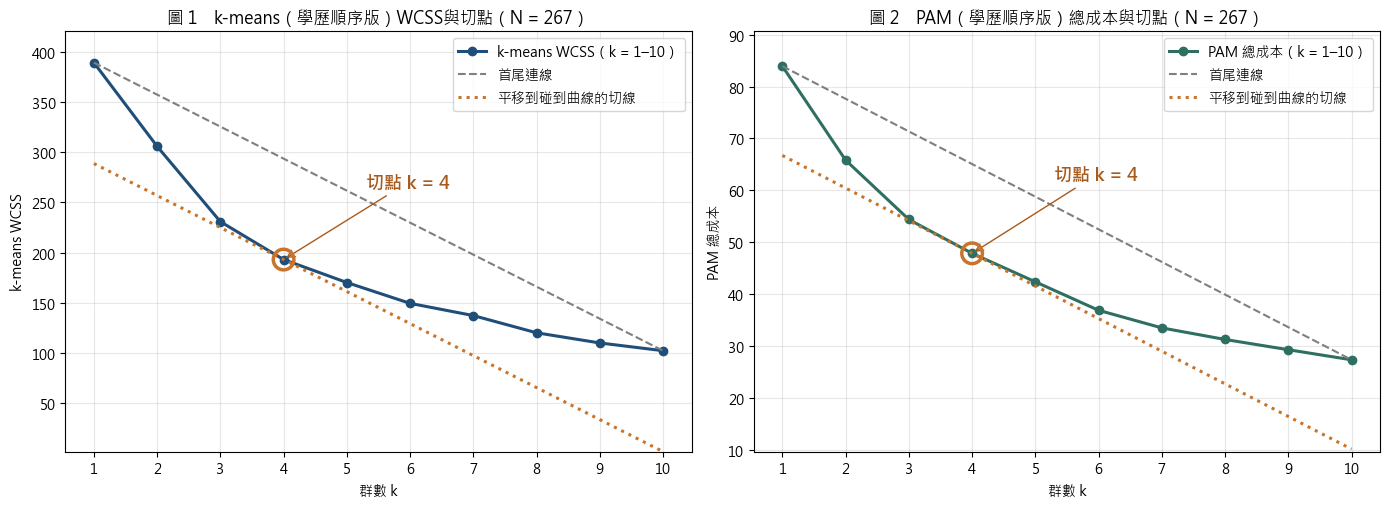

In [5]:
rows = []
for k in range(1, 11):
    lk, wk = kmeans(X_ord, k, n_init=50, seed=20261110 + k)
    lp, cp, _ = pam(D_ord, k)
    rows.append({"k": k, "k-means WCSS": wk,
                 "k-means 輪廓係數": silhouette_D(eucl(X_ord), lk) if k > 1 else np.nan,
                 "PAM 總成本": cp, "PAM 輪廓係數": silhouette_D(D_ord, lp) if k > 1 else np.nan,
                 "k-means 最小群": int(np.bincount(lk, minlength=k).min()), "PAM 最小群": int(np.bincount(lp, minlength=k).min())})
ch = pd.DataFrame(rows).set_index("k")
ch.insert(1, "k-means 減少幅度（%）", 100 * (-ch["k-means WCSS"].diff()) / ch["k-means WCSS"].shift())
ch.insert(4, "PAM 減少幅度（%）", 100 * (-ch["PAM 總成本"].diff()) / ch["PAM 總成本"].shift())
k_el_km, k_el_pam = tangent_k(ch["k-means WCSS"]), tangent_k(ch["PAM 總成本"])
print(f"表 3　學歷順序版：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = {len(df)}）")
display(ch.round(3))
print(f"平移首尾連線切點：k-means 順序版 k = {k_el_km}（原版 k = 4）；PAM 順序版 k = {k_el_pam}（原版 k = 4）")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, col, kk, title, color in [(axes[0], "k-means WCSS", k_el_km, "圖 1　k-means（學歷順序版）WCSS", "#1f4e79"),
                                  (axes[1], "PAM 總成本", k_el_pam, "圖 2　PAM（學歷順序版）總成本", "#2f6f62")]:
    w = ch[col]; ks = np.array(w.index, float)
    chord = w.iloc[0] + (w.iloc[-1] - w.iloc[0]) / 9 * (ks - 1)
    gap = (chord - w.values).max()
    ax.plot(ks, w.values, marker="o", color=color, linewidth=2.2, label=f"{col}（k = 1–10）")
    ax.plot([1, 10], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", label="首尾連線")
    ax.plot(ks, chord - gap, linestyle=":", color="#C8742B", linewidth=2.2, label="平移到碰到曲線的切線")
    ax.scatter([kk], [w.loc[kk]], s=220, facecolors="none", edgecolors="#C8742B", linewidths=2.5, zorder=4)
    ax.annotate(f"切點 k = {kk}", xy=(kk, w.loc[kk]), xytext=(kk + 1.3, w.loc[kk] + (w.max() - w.min()) * 0.25),
                fontsize=13, color="#A85A1B", fontweight="bold", arrowprops=dict(arrowstyle="->", color="#A85A1B"))
    ax.set_title(f"{title}與切點（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel(col); ax.set_xticks(ks)
    ax.set_ylim(min((chord - gap).min(), w.min()) * 0.95, w.max() * 1.08)
    ax.legend(loc="upper right", fontsize=10); ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_cluster_education_ordinal_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "ordinal_choose_k.png", dpi=200)
plt.show()


In [6]:
K = 4
lab = {}
lab["k-means 原版"] = relabel_by_size(kmeans(X_nom, K, n_init=50, seed=20261110 + K)[0])
lab["k-means 順序版"] = relabel_by_size(kmeans(X_ord, K, n_init=50, seed=20261110 + K)[0])
lab["PAM 原版"] = relabel_by_size(pam(D_nom, K)[0])
lab["PAM 順序版"] = relabel_by_size(pam(D_ord, K)[0])
for k_, v in lab.items():
    print(k_, "各群人數：", pd.Series(v).value_counts().sort_index().to_dict())
assert sorted(pd.Series(lab["k-means 原版"]).value_counts().tolist()) == [64, 65, 68, 70], "k-means 原版應重現 70／68／65／64"
assert sorted(pd.Series(lab["PAM 原版"]).value_counts().tolist()) == [51, 66, 74, 76], "PAM 原版應重現 76／74／66／51"

def describe(g):
    col = {"人數": len(g), "平均年齡": g["age"].mean(), "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in PARTIES:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    return col

profiles = {}
for name in ["k-means 順序版", "PAM 順序版"]:
    df["_c"] = lab[name]
    p = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    p["全樣本"] = pd.Series(describe(df))
    profiles[name] = p
    print(f"表 {4 if name.startswith('k') else 5}　{name} k = 4 各群特徵（N = {len(df)}；百分比分母為該群人數）")
    display(p.round(1))
df = df.drop(columns="_c")


k-means 原版 各群人數： {1: 70, 2: 68, 3: 65, 4: 64}
k-means 順序版 各群人數： {1: 85, 2: 80, 3: 69, 4: 33}
PAM 原版 各群人數： {1: 76, 2: 74, 3: 66, 4: 51}
PAM 順序版 各群人數： {1: 97, 2: 64, 3: 59, 4: 47}
表 4　k-means 順序版 k = 4 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,85.0,80.0,69.0,33.0,267.0
平均年齡,53.2,49.0,54.9,50.0,52.0
女性（%）,44.7,43.8,23.2,33.3,37.5
學歷：研究所（%）,72.9,76.2,47.8,39.4,63.3
學歷：大學（%）,20.0,21.2,30.4,45.5,26.2
學歷：大學以下（%）,7.1,2.5,21.7,15.2,10.5
政黨：國民黨（%）,100.0,0.0,0.0,0.0,31.8
政黨：民進黨（%）,0.0,100.0,0.0,0.0,30.0
政黨：民眾黨（%）,0.0,0.0,0.0,24.2,3.0
政黨：其他政黨（%）,0.0,0.0,0.0,75.8,9.4


表 5　PAM 順序版 k = 4 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,97.0,64.0,59.0,47.0,267.0
平均年齡,53.8,48.2,54.7,50.1,52.0
女性（%）,23.7,87.5,20.3,19.1,37.5
學歷：研究所（%）,81.4,75.0,32.2,48.9,63.3
學歷：大學（%）,14.4,17.2,50.8,31.9,26.2
學歷：大學以下（%）,4.1,7.8,16.9,19.1,10.5
政黨：國民黨（%）,69.1,26.6,0.0,2.1,31.8
政黨：民進黨（%）,22.7,64.1,10.2,23.4,30.0
政黨：民眾黨（%）,2.1,3.1,5.1,2.1,3.0
政黨：其他政黨（%）,6.2,1.6,20.3,12.8,9.4


表 6　四個版本比較（k = 4；抽 80%＝214 人重跑 50 次，四版本用同一批抽樣；排除報導／約略年齡者 N = 245）


,elbow 切點 k,與同方法原版的 ARI,抽 80% 重跑 平均 ARI,抽 80% 重跑 ARI ≥ 0.9（%）,排除 22 人後 ARI
k-means 原版,4,1.000,0.886,50.0,0.914
k-means 順序版,4,0.543,0.989,96.0,1.000
PAM 原版,4,1.000,0.458,14.0,0.382
PAM 順序版,4,0.202,0.374,12.0,0.194


k-means 順序版 vs PAM 順序版 的 ARI = 0.308 （原版兩方法之間為 0.192 ）


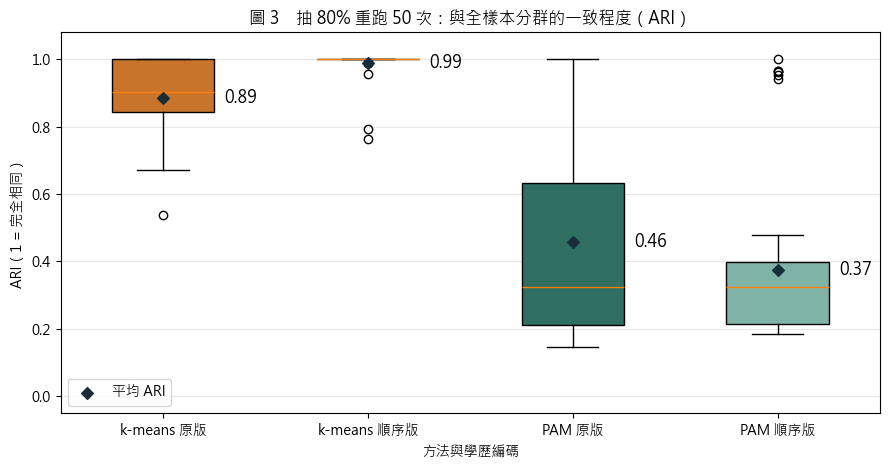

In [7]:
rng = np.random.default_rng(20261110)
n = len(df); m = int(round(0.8 * n))
recs = []
for r in range(50):
    idx = np.sort(rng.choice(n, m, replace=False))
    sub = {"k-means 原版": kmeans(X_nom[idx], K, n_init=10, seed=20261110 + 100 + r)[0],
           "k-means 順序版": kmeans(X_ord[idx], K, n_init=10, seed=20261110 + 100 + r)[0],
           "PAM 原版": pam(D_nom[np.ix_(idx, idx)], K)[0],
           "PAM 順序版": pam(D_ord[np.ix_(idx, idx)], K)[0]}
    recs.append({k_: ari(lab[k_][idx], v) for k_, v in sub.items()})
boot = pd.DataFrame(recs)
keep = np.where(df["G1_age_basis"].isin(["birth_date", "existing_source"]).to_numpy())[0]
excl = {"k-means 原版": ari(lab["k-means 原版"][keep], kmeans(X_nom[keep], K, n_init=50, seed=20261110 + K)[0]),
        "k-means 順序版": ari(lab["k-means 順序版"][keep], kmeans(X_ord[keep], K, n_init=50, seed=20261110 + K)[0]),
        "PAM 原版": ari(lab["PAM 原版"][keep], pam(D_nom[np.ix_(keep, keep)], K)[0]),
        "PAM 順序版": ari(lab["PAM 順序版"][keep], pam(D_ord[np.ix_(keep, keep)], K)[0])}
summary = pd.DataFrame({
    "elbow 切點 k": [4, k_el_km, 4, k_el_pam],
    "與同方法原版的 ARI": [1.0, ari(lab["k-means 原版"], lab["k-means 順序版"]), 1.0, ari(lab["PAM 原版"], lab["PAM 順序版"])],
    "抽 80% 重跑 平均 ARI": boot.mean().values,
    "抽 80% 重跑 ARI ≥ 0.9（%）": 100 * (boot >= 0.9).mean().values,
    "排除 22 人後 ARI": [excl[k_] for k_ in boot.columns]}, index=boot.columns)
print(f"表 6　四個版本比較（k = 4；抽 80%＝{m} 人重跑 50 次，四版本用同一批抽樣；排除報導／約略年齡者 N = {len(keep)}）")
display(summary.round(3))
print("k-means 順序版 vs PAM 順序版 的 ARI =", round(ari(lab["k-means 順序版"], lab["PAM 順序版"]), 3),
      "（原版兩方法之間為", round(ari(lab["k-means 原版"], lab["PAM 原版"]), 3), "）")

fig, ax = plt.subplots(figsize=(9, 4.8))
pos = np.arange(4)
bp = ax.boxplot([boot[c] for c in boot.columns], positions=pos, widths=0.5, patch_artist=True)
for patch, col in zip(bp["boxes"], ["#C8742B", "#E3A86F", "#2f6f62", "#7FB3A6"]):
    patch.set_facecolor(col)
means = boot.mean().values
ax.scatter(pos, means, marker="D", color="#182D39", zorder=4, label="平均 ARI")
for x, v in zip(pos, means):
    ax.text(x + 0.3, v, f"{v:.2f}", va="center", fontsize=12)
ax.set_xticks(pos); ax.set_xticklabels(boot.columns)
ax.set_ylim(-0.05, 1.08)
ax.set_title("圖 3　抽 80% 重跑 50 次：與全樣本分群的一致程度（ARI）")
ax.set_xlabel("方法與學歷編碼"); ax.set_ylabel("ARI（1 = 完全相同）")
ax.legend(loc="lower left"); ax.grid(alpha=.3, axis="y")
fig.tight_layout()
fig.savefig(asset_dir / "ordinal_stability.png", dpi=200)
plt.show()


### 結果說明

**樣本。** 267 位候選人，G1–G6 無缺值。順序版的 k-means 特徵為 10 欄（原版 12 欄）；Gower 距離兩兩平均由 0.438 降為 0.406（學歷差距變小）。

**選 k（表 3、圖 1–2）。** 兩種方法改成順序編碼後，平移首尾連線的切點仍是 **k = 4**，和原版一致，k 的選擇不受學歷編碼影響。順序版 PAM 的輪廓係數（k = 4 為 0.254）略高於原版（0.226），但仍偏低，而且一樣隨 k 增加而上升。

**k-means 順序版的四群（表 4）。** 85／80／69／33 人，**每群都是單一政黨類別**：第 1 群全為國民黨、第 2 群全為民進黨、第 3 群全為無黨籍、第 4 群為民眾黨（24%）與其他政黨（76%）。學歷、性別等只在群內呈現差異（例如無黨籍群的大學以下 22%、首次參選 42%）。原因是學歷由 3 欄縮成 1 欄、距離平方最多 1，政黨的 5 個虛擬變數（距離平方 2）在距離中占比更高。和原版 k-means 的 ARI 為 0.543。

**PAM 順序版的四群（表 5）。** 97／64／59／47 人：第 1 群國民黨 69%、研究所 81%；第 2 群女性 88%、政治家族 66%、民進黨 64%；第 3 群無黨籍 64%、全都曾參選、大學 51%；第 4 群全部首次參選、無黨籍 60%。和原版 PAM（女性／民進黨年輕男性／國民黨年長男性／無黨籍素人）相比，雖然仍有「女性」「首次參選」的群，但成員重組很多，ARI 只有 0.202。

**穩定度（表 6、圖 3）。**

| 版本 | elbow 切點 | 與同方法原版 ARI | 抽 80% 重跑平均 ARI | 排除 22 人後 ARI |
| --- | --- | --- | --- | --- |
| k-means 原版（學歷 one-hot） | 4 | 1.000 | 0.886 | 0.914 |
| k-means 順序版 | 4 | 0.543 | 0.989 | 1.000 |
| PAM 原版（學歷相同／不同） | 4 | 1.000 | 0.458 | 0.382 |
| PAM 順序版 | 4 | 0.202 | 0.374 | 0.194 |

k-means 兩版都穩定，順序版更穩，因為它幾乎只依政黨分群；PAM 兩版都不穩，換掉部分樣本或改變學歷編碼，分群就大幅改變。順序版兩方法之間的 ARI 為 0.308（原版為 0.192）。

**解讀。** 學歷的編碼方式不影響 k = 4 的選擇，但會改變分群內容：k-means 在兩種編碼下都主要依政黨分群（順序版甚至完全等於政黨）；PAM 的群隨編碼與樣本改變，代表背景資料中除了政黨之外，沒有穩定的群結構。這支持先前的建議：若需要穩定的分組，k-means 或直接以政黨（或政黨 × 其他變數的規則型類型）分組較可靠，並需說明分群主要反映政黨；PAM 的類型只適合作描述。

**限制。** 順序編碼假設三級學歷等距（大學以下→大學＝大學→研究所）；若改用其他間距（例如 0／1／2 不縮放）結果可能不同。k-means、PAM 以 numpy 實作，因為本機的應用程式控制原則封鎖了 scikit-learn。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
